In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Makes plots show inside the notebook
%matplotlib inline

In [2]:
# Load both files
train_df = pd.read_csv('../data/train_u6lujuX_CVtuZ9i.csv')
test_df  = pd.read_csv('../data/test_Y3wMUE5_7gLdaTN.csv')

# Check their shapes before combining
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

# Combine into one master dataset
df = pd.concat([train_df, test_df], ignore_index=True)
print("Combined shape:", df.shape)

df.head()

Train shape: (614, 13)
Test shape: (367, 12)
Combined shape: (981, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df = df.dropna(subset=['Loan_Status'])
print("Shape after dropping missing targets:", df.shape)

Shape after dropping missing targets: (614, 13)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
}).sort_values('Missing %', ascending=False)

print(missing_df[missing_df['Missing Count'] > 0])

                  Missing Count  Missing %
Credit_History               50   8.143322
Self_Employed                32   5.211726
LoanAmount                   22   3.583062
Dependents                   15   2.442997
Loan_Amount_Term             14   2.280130
Gender                       13   2.117264
Married                       3   0.488599


Loan_Status
Y    422
N    192
Name: count, dtype: int64


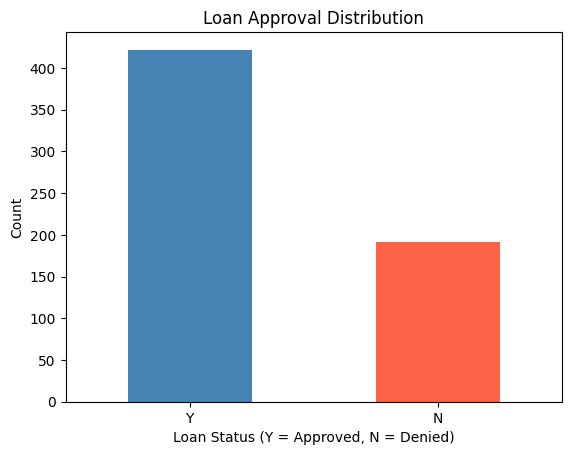

In [6]:
print(df['Loan_Status'].value_counts())

df['Loan_Status'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'])
plt.title('Loan Approval Distribution')
plt.xlabel('Loan Status (Y = Approved, N = Denied)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

# Phase 1 — Data Exploration
**Author:** Sabeeh  
**Dataset:** Loan Prediction Dataset (Kaggle)

## Key Findings

### Dataset Overview
- Combined train + test files into one master dataset
- Final working dataset: **614 rows, 13 columns**
- Dropped 367 rows from test file (no Loan_Status label)

### Missing Values
- 7 columns contain missing data
- Highest: Credit_History (8.1%) — most critical feature
- Strategy: median fill for numerical, mode fill for categorical

### Target Variable
- Approved (Y): 422 (68.7%)
- Denied (N): 192 (31.3%)
- Dataset is **imbalanced** — will handle with class weighting in Phase 3

### Data Types
- 8 categorical (str) columns → require encoding in Phase 2
- 4 numerical (float64/int64) columns → require scaling in Phase 2
- Loan_ID → will be dropped (identifier, not a feature)

### Next Step
Phase 2 — Preprocessing & Feature Engineering